In [43]:
import operator
from typing import Annotated, Literal, TypedDict
from langgraph.graph import START, END, StateGraph
from langgraph.types import Send, Overwrite

In [44]:
class State(TypedDict):
    numbers: list[int]
    results: Annotated[list[int], operator.add]
    sum: Annotated[int, operator.add]
    product: Annotated[int, operator.mul]

def add_one(job):
    return {"results": [job["number"] + 1], "sum": job["number"], "product": job["number"]}

def list_numbers(state: State):
    return {"numbers": [1,2,3,4,5], "results": [], "sum": 0, "product": Overwrite(value=1)}

def choose_next(state: State):
    print(state)
    if (sum(state["numbers"]) > 10):
        return "success"
    else:
        return "fail"

def fan_out(state: State):
    return [Send("add_one", {"number": number}) for number in state["numbers"]]

builder = StateGraph(State)
builder.add_node("list_numbers", list_numbers)
builder.add_node("add_one", add_one)

builder.add_edge(START, "list_numbers")
builder.add_conditional_edges("list_numbers", fan_out, ["add_one"])
builder.add_edge("add_one", END)

graph = builder.compile()

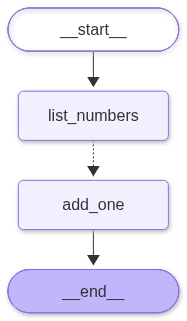

In [14]:
graph

In [45]:
graph.invoke({})

{'numbers': [1, 2, 3, 4, 5],
 'results': [2, 3, 4, 5, 6],
 'sum': 15,
 'product': 120}